# 07 — Is the drift a seasonal cycle?

*27 Nov 2026.* EMOS refitted on a 90-day rolling window beats static EMOS on val (CRPS 77.5 vs 80.0 MW), and the
coefficients of the rolling fits move over time. Two explanations: the static model misses a **seasonal
cycle** (which a 90-day window follows automatically), or the relation between ensemble and observations
**drifts** over the years. Seasonal EMOS adds one annual harmonic to the static model:

- μ = a(t) + b(t)·mean(p_00…p_14)
- σ² = (c² + d²·var(p_01…p_14))·exp(g(t))
- a(t) = a0 + a1 sin 2πt + a2 cos 2πt, likewise b(t); g(t) = g1 sin 2πt + g2 cos 2πt (t: fraction of the year)

fitted once on the train fold per zone and UTC hour. If it closes most of the gap to the 90-day window, the gain
is seasonal; if not, something drifts. **Validation fold only.**

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windai.data.build import load_dataset
from windai.data.splits import training_rows, evaluation_rows, history_rows
from windai.models.EMOS import EMOS, SeasonalEMOS, RollingEMOS, ensemble_stats
from windai.models.baselines import Climatology
from windai.models import censored_normal as cn
from windai.evaluation.evaluate import score

pd.set_option("display.width", 200)
df, curve = load_dataset("train", fit="val")
train, history, val = training_rows(df, "val"), history_rows(df, "val"), evaluation_rows(df, "val")
hidden = val.drop(columns=["power", "cf"])
y = val["power"].to_numpy()

models = {"climatology": (Climatology(), train), "emos_static": (EMOS(), train),
          "emos_seasonal": (SeasonalEMOS(), train), "emos_rolling_90": (RollingEMOS(90), history)}
fitted, fc, seconds = {}, {}, {}
for name, (model, data) in models.items():
    t0 = time.time()
    fitted[name] = model.fit(data)
    fc[name] = fitted[name].predict(hidden)
    seconds[name] = time.time() - t0
pd.Series(seconds, name="seconds").round(1)

climatology          0.5
emos_static          1.2
emos_seasonal        4.9
emos_rolling_90    186.6
Name: seconds, dtype: float64

## 1. Scores on val

In [2]:
overall = pd.DataFrame({name: score(f, y).loc["all"] for name, f in fc.items()}).T
overall["crpss"] = 1 - overall["crps_q"] / overall.loc["climatology", "crps_q"]
cols = ["crps_q", "crps_exact", "crpss", "rmse", "cov_50", "cov_80", "cov_90", "cov_95"]
overall[[c for c in cols if c in overall.columns]].round(3)

,crps_q,crps_exact,crpss,rmse,cov_50,cov_80,cov_90,cov_95
climatology,166.565,NaN,0.000,331.300,0.477,0.778,0.885,0.936
emos_static,80.004,79.223,0.520,164.172,0.568,0.851,0.921,0.957
emos_seasonal,78.626,77.858,0.528,162.193,0.548,0.838,0.914,0.951
emos_rolling_90,77.507,76.757,0.535,160.654,0.516,0.810,0.889,0.932


In [3]:
# Exact CRPS per zone (MW), and the share of the static-to-90-day gap that the seasonal model closes
per_zone = pd.DataFrame({name: score(f, y)["crps_exact"] for name, f in fc.items() if name != "climatology"})
per_zone["gap closed"] = ((per_zone["emos_static"] - per_zone["emos_seasonal"])
                          / (per_zone["emos_static"] - per_zone["emos_rolling_90"]))
per_zone.round(3)

,emos_static,emos_seasonal,emos_rolling_90,gap closed
zone,,,,
ELSPOT NO1,30.678,30.547,31.469,-0.166
ELSPOT NO2,94.954,91.849,91.971,1.041
ELSPOT NO3,124.927,123.618,123.684,1.053
ELSPOT NO4,66.332,65.419,59.903,0.142
all,79.223,77.858,76.757,0.553


**Findings (scores).** Seasonal EMOS closes **55 %** of the static-to-90-day gap overall (exact CRPS 79.2 → 77.9;
90-day 76.8), but the zones differ completely:
- **NO2, NO3: the whole gain is seasonal.** Seasonal EMOS matches the 90-day window (91.8 vs 92.0; 123.6 vs 123.7).
- **NO4: drift.** The seasonal model closes only 14 % of the gap (66.3 → 65.4, rolling 59.9).
- **NO1:** the rolling window is worse than static, the seasonal model slightly better: short windows cost
  more than they gain in the smallest zone.

Seasonal EMOS keeps the static model's calibrated coverage (95.1 % at 95 %), whereas the 90-day window is too
narrow (93.2 %): its short fits underestimate the scale.

## 2. The seasonal terms
In-sample (train) gain in mean log-likelihood of seasonal over static EMOS, and the size of the cycles:
amplitude of a(t) and b(t) (√(x1² + x2²)), and of the scale factor exp(g(t)/2) for σ, as the median over the 24
hourly models of each zone.

In [4]:
ps, pst = fitted["emos_seasonal"].summary(), fitted["emos_static"].summary()
gain = (pst["loss"] - ps["loss"]).groupby(level="zone").median()      # loss = mean negative log-likelihood
amp = pd.DataFrame({
    "loglik gain (train, per value)": gain,
    "amp a": np.hypot(ps["a1"], ps["a2"]).groupby(level="zone").median(),
    "amp b": np.hypot(ps["b1"], ps["b2"]).groupby(level="zone").median(),
    "sigma factor max/min": np.exp(np.hypot(ps["g1"], ps["g2"])).groupby(level="zone").median(),
    "converged": ps["converged"].groupby(level="zone").mean(),
})
amp.round(3)

,"loglik gain (train, per value)",amp a,amp b,sigma factor max/min,converged
zone,,,,,
ELSPOT NO1,0.076,0.057,0.117,1.493,1.0
ELSPOT NO2,0.050,0.044,0.026,1.112,1.0
ELSPOT NO3,0.059,0.031,0.065,1.400,1.0
ELSPOT NO4,0.051,0.025,0.098,1.594,1.0


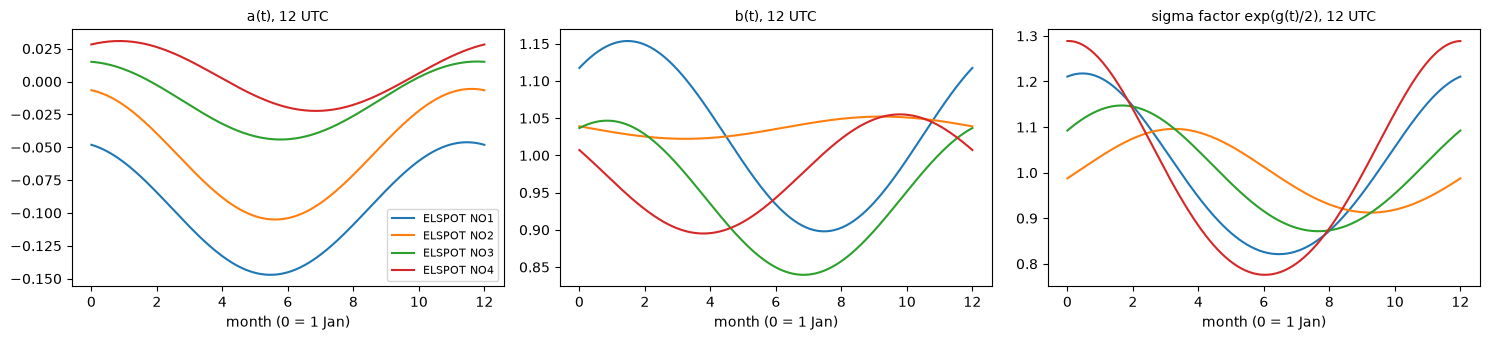

In [5]:
# The fitted cycles over the year for one hour (12 UTC): a(t), b(t) and the sigma factor, per zone
t = np.linspace(0, 1, 200)
B = np.column_stack([np.ones_like(t), np.sin(2 * np.pi * t), np.cos(2 * np.pi * t)])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for zone in ps.index.get_level_values("zone").unique():
    p = ps.loc[(zone, 12), ["a0", "a1", "a2", "b0", "b1", "b2", "g1", "g2"]].astype(float)
    axes[0].plot(t * 12, B @ p[["a0", "a1", "a2"]].to_numpy(), label=zone)
    axes[1].plot(t * 12, B @ p[["b0", "b1", "b2"]].to_numpy())
    axes[2].plot(t * 12, np.exp(0.5 * B[:, 1:] @ p[["g1", "g2"]].to_numpy()))
for ax, title in zip(axes, ["a(t)", "b(t)", "sigma factor exp(g(t)/2)"]):
    ax.set_title(f"{title}, 12 UTC", fontsize=10); ax.set_xlabel("month (0 = 1 Jan)")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Findings (terms).** The cycles are clear in every zone and every fit converged:
- the intercept is ~0.03–0.06 CF lower in summer;
- b is mostly lower in summer;
- the scale is largest in winter and smallest in early summer, by a factor 1.1–1.6 between them.

The train log-likelihood rises by 0.05–0.08 per value for 6 extra parameters on ~1,100 values per fit.

## 3. Bias and calibration by month on val
Mean error (observed − forecast mean) as a share of capacity, and the mean PIT, per zone and month. A seasonal
model should remove a bias that follows the calendar; a bias that persists for months regardless points to drift.

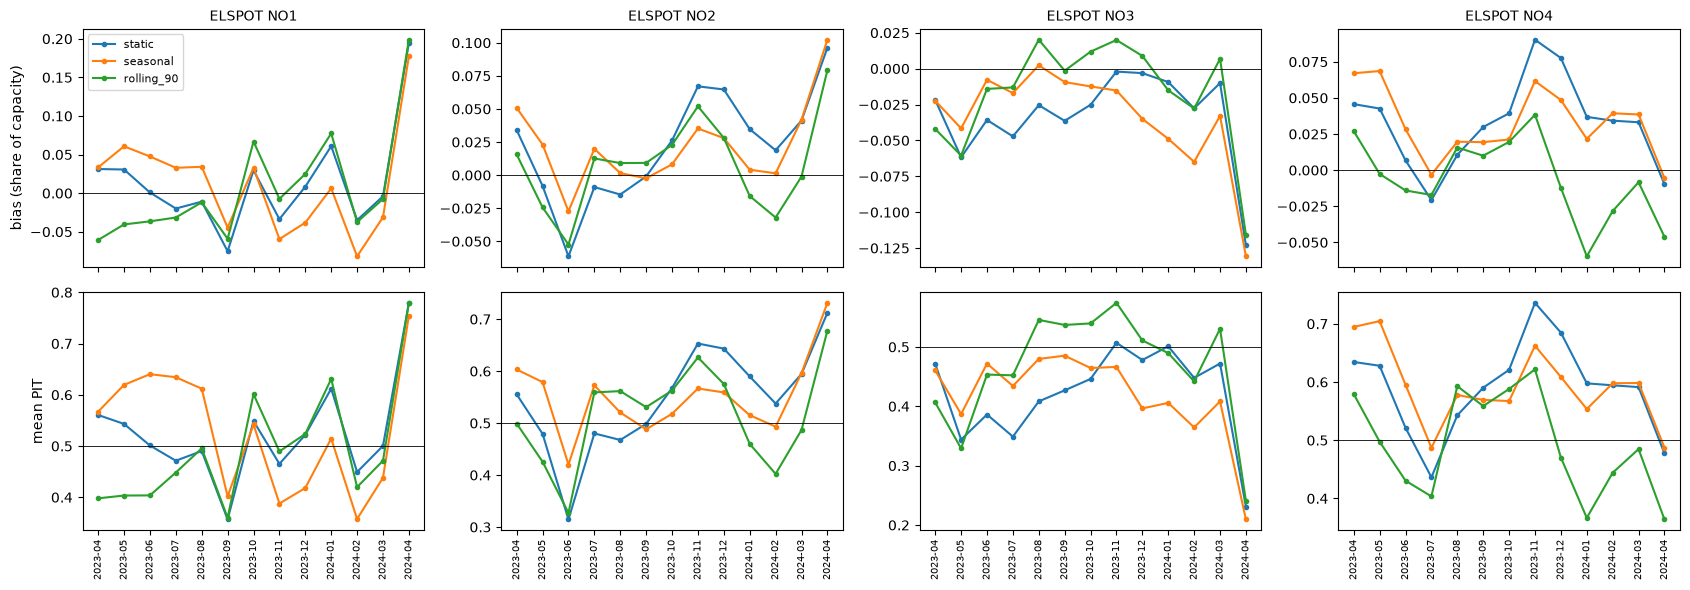

In [6]:
obs = ~np.isnan(y)
v = val.loc[obs, ["zone", "target_time", "capacity_mw"]].copy()
v["month"] = pd.to_datetime(v["target_time"]).dt.strftime("%Y-%m")
emos_names = ["emos_static", "emos_seasonal", "emos_rolling_90"]
for n in emos_names:
    v[f"bias {n}"] = (y[obs] - fc[n].point[obs]) / v["capacity_mw"]
    v[f"pit {n}"] = fc[n].pit_fn(y[obs], rng=0)

fig, axes = plt.subplots(2, 4, figsize=(17, 6), sharex=True)
for j, (zone, g) in enumerate(v.groupby("zone")):
    mon = g.groupby("month").mean(numeric_only=True)
    for n in emos_names:
        axes[0, j].plot(mon.index, mon[f"bias {n}"], marker="o", ms=3, label=n.replace("emos_", ""))
        axes[1, j].plot(mon.index, mon[f"pit {n}"], marker="o", ms=3)
    axes[0, j].axhline(0, color="k", lw=0.6); axes[1, j].axhline(0.5, color="k", lw=0.6)
    axes[0, j].set_title(zone, fontsize=10)
    for ax in axes[:, j]:
        ax.tick_params(axis="x", rotation=90, labelsize=7)
axes[0, 0].set_ylabel("bias (share of capacity)"); axes[1, 0].set_ylabel("mean PIT")
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [7]:
# Mean PIT per zone over the whole val year (0.5 = unbiased)
v.groupby("zone")[[f"pit {n}" for n in emos_names]].mean().round(3)

,pit emos_static,pit emos_seasonal,pit emos_rolling_90
zone,,,
ELSPOT NO1,0.504,0.513,0.474
ELSPOT NO2,0.535,0.538,0.504
ELSPOT NO3,0.436,0.434,0.484
ELSPOT NO4,0.598,0.600,0.502


**Findings (monthly).** (The 2024-04 point covers only the first two target days in April and is noise.)
- The seasonal model **does not fix the year-level biases**. Its mean PIT is 0.434 in NO3 (static 0.436) and
  0.600 in NO4 (static 0.598).
- **NO4** is under-forecast by all fixed models through most of the val year, and most strongly in Nov–Dec 2023.
  The 90-day window follows it down, overshooting in Jan–Apr 2024 (PIT ≈ 0.37). That's a level shift, not a cycle.
- **NO3** is over-forecast by static EMOS through summer and autumn 2023. Seasonal EMOS improves its CRPS through
  the seasonal scale rather than the bias.

**Conclusion.** The rolling-window gain has two sources:
- **seasonality** (cycles in intercept, slope and scale), which a fixed model with annual harmonics captures
  just as well, keeping its coverage;
- **genuine drift** in the level of NO4, and partly NO3, between train and val, which only refitting follows.

For the thesis, conditioning on the ensemble does not make the conditional distribution stationary. Season
should be a covariate, and the drift needs either recent data or a time-varying model.